# Entrenamiento de XGBoost

**Maestría en Inteligencia Artificial MAIA**

**Proyecto - Desarrollo de Soluciones**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

Entrenamiento supervisado con `XGBClassifier` usando `train.csv` y `test.csv` procesados. La busqueda de hiperparametros se valida con `StratifiedKFold` y optimiza `f1_macro`, que es la metrica principal para este problema multiclase desbalanceado.

In [11]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

try:
    from xgboost import XGBClassifier
except Exception as exc:
    raise ImportError(
        "No se pudo importar XGBoost. En macOS suele faltar el runtime OpenMP; "
        "instalalo con `brew install libomp` y vuelve a ejecutar el kernel."
    ) from exc

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

## Configuracion

Los identificadores de sujeto y grabacion se excluyen del entrenamiento para evitar fuga de informacion. Si se quiere comparar contra un modelo que use estas columnas, agregarlas explicitamente a `FEATURE_COLUMNS` despues de justificarlo.

In [12]:
RANDOM_STATE = 42
CV_SPLITS = 5
N_ITER_SEARCH = 20
SCORING = "f1_macro"

TARGET_COLUMN = "y"
ID_COLUMNS = ["recording_id", "subject_code"]

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data" / "processed" / "train.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

TRAIN_PATH, TEST_PATH, MODEL_DIR

(PosixPath('/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/processed/train.csv'),
 PosixPath('/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/processed/test.csv'),
 PosixPath('/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/models'))

## Carga de datos

In [13]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Train shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

display(train_df.head())
display(train_df[TARGET_COLUMN].value_counts().sort_index().rename("train_count"))
display(test_df[TARGET_COLUMN].value_counts().sort_index().rename("test_count"))

Train shape: (150272, 17)
Test shape:  (45207, 17)


,EEG_Fpz-Cz__delta_power_abs,EEG_Fpz-Cz__delta_power_rel,EEG_Fpz-Cz__theta_power_abs,EEG_Fpz-Cz__theta_power_rel,EEG_Fpz-Cz__alpha_power_abs,EEG_Fpz-Cz__alpha_power_rel,EEG_Fpz-Cz__sigma_power_abs,EEG_Fpz-Cz__sigma_power_rel,EEG_Fpz-Cz__beta_power_abs,EEG_Fpz-Cz__beta_power_rel,EEG_Fpz-Cz__delta_alpha_ratio,EEG_Fpz-Cz__theta_alpha_ratio,EEG_Fpz-Cz__sef95,EEG_Fpz-Cz__spectral_entropy,y,recording_id,subject_code
0,441.49713,0.869095,27.724798,0.054577,10.516427,0.020702,4.884139,0.009615,20.179281,0.039723,41.981667,2.636332,20.25,0.595699,0,SC4481F0,48
1,485.16055,0.848066,44.572014,0.077912,13.932046,0.024353,4.607310,0.008054,15.736931,0.027508,34.823353,3.199244,7.50,0.540363,0,SC4481F0,48
2,431.59152,0.854248,33.038925,0.065394,11.134102,0.022038,6.312143,0.012494,21.599360,0.042752,38.763030,2.967363,13.25,0.524626,0,SC4481F0,48
3,510.90277,0.878044,32.257076,0.055437,10.797283,0.018556,5.808200,0.009982,21.244148,0.036510,47.317720,2.987518,12.25,0.515004,0,SC4481F0,48
4,622.32336,0.746474,48.513107,0.058191,24.586466,0.029491,23.989834,0.028776,127.950350,0.153476,25.311625,1.973163,44.25,0.692052,0,SC4481F0,48


y
0    49565
1    16445
2    53593
3    10579
4    20090
Name: train_count, dtype: int64

y
0    16386
1     5077
2    15539
3     2460
4     5745
Name: test_count, dtype: int64

## Preparacion de matrices

In [14]:
missing_columns = set(train_df.columns) ^ set(test_df.columns)
if missing_columns:
    raise ValueError(f"Train y test no tienen las mismas columnas: {missing_columns}")

feature_columns = [
    column
    for column in train_df.columns
    if column not in [TARGET_COLUMN, *ID_COLUMNS]
]

X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(train_df[TARGET_COLUMN])
y_test = label_encoder.transform(test_df[TARGET_COLUMN])
class_labels = label_encoder.classes_

sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

print(f"Numero de features: {len(feature_columns)}")
print(f"Clases: {class_labels.tolist()}")
display(pd.Series(feature_columns, name="features"))

Numero de features: 14
Clases: [0, 1, 2, 3, 4]


0       EEG_Fpz-Cz__delta_power_abs
1       EEG_Fpz-Cz__delta_power_rel
2       EEG_Fpz-Cz__theta_power_abs
3       EEG_Fpz-Cz__theta_power_rel
4       EEG_Fpz-Cz__alpha_power_abs
5       EEG_Fpz-Cz__alpha_power_rel
6       EEG_Fpz-Cz__sigma_power_abs
7       EEG_Fpz-Cz__sigma_power_rel
8        EEG_Fpz-Cz__beta_power_abs
9        EEG_Fpz-Cz__beta_power_rel
10    EEG_Fpz-Cz__delta_alpha_ratio
11    EEG_Fpz-Cz__theta_alpha_ratio
12                EEG_Fpz-Cz__sef95
13     EEG_Fpz-Cz__spectral_entropy
Name: features, dtype: object

## Busqueda de hiperparametros con validacion cruzada

La busqueda usa `RandomizedSearchCV` con CV estratificada y selecciona el mejor modelo por `f1_macro`.

In [15]:
base_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(class_labels),
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

param_distributions = {
    "n_estimators": [200, 300, 500, 700],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "gamma": [0, 0.1, 0.3, 0.5, 1.0],
    "reg_alpha": [0, 0.01, 0.1, 0.5],
    "reg_lambda": [0.5, 1.0, 1.5, 2.0],
}

cv = StratifiedKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_distributions,
    n_iter=N_ITER_SEARCH,
    scoring=SCORING,
    cv=cv,
    verbose=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
)

search.fit(X_train, y_train, sample_weight=sample_weights)

print(f"Mejor {SCORING} CV: {search.best_score_:.4f}")
print("Mejores hiperparametros:")
display(search.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END colsample_bytree=0.7, gamma=1.0, learning_rate=0.08, max_depth=8, min_child_weight=1, n_estimators=300, reg_alpha=0.1, reg_lambda=1.0, subsample=0.9; total time=  24.3s
[CV] END colsample_bytree=0.7, gamma=1.0, learning_rate=0.08, max_depth=8, min_child_weight=1, n_estimators=300, reg_alpha=0.1, reg_lambda=1.0, subsample=0.9; total time=  24.5s
[CV] END colsample_bytree=0.7, gamma=1.0, learning_rate=0.08, max_depth=8, min_child_weight=1, n_estimators=300, reg_alpha=0.1, reg_lambda=1.0, subsample=0.9; total time=  24.5s
[CV] END colsample_bytree=0.7, gamma=1.0, learning_rate=0.08, max_depth=8, min_child_weight=1, n_estimators=300, reg_alpha=0.1, reg_lambda=1.0, subsample=0.9; total time=  24.5s
[CV] END colsample_bytree=0.7, gamma=1.0, learning_rate=0.08, max_depth=8, min_child_weight=1, n_estimators=300, reg_alpha=0.1, reg_lambda=1.0, subsample=0.9; total time=  25.4s
[CV] END colsample_bytree=0.8, gamma=0, learning

{'subsample': 0.9,
 'reg_lambda': 1.0,
 'reg_alpha': 0.1,
 'n_estimators': 300,
 'min_child_weight': 1,
 'max_depth': 8,
 'learning_rate': 0.08,
 'gamma': 1.0,
 'colsample_bytree': 0.7}

In [16]:
cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cv_summary_columns = [
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "std_train_score",
    "params",
]
display(cv_results[cv_summary_columns].head(10))

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
0,1,0.719845,0.003516,0.826813,0.001281,"{'subsample': 0.9, 'reg_lambda': 1.0, 'reg_alp..."
1,2,0.719406,0.004080,0.808181,0.000543,"{'subsample': 1.0, 'reg_lambda': 0.5, 'reg_alp..."
10,3,0.718985,0.002811,0.889110,0.000837,"{'subsample': 0.9, 'reg_lambda': 0.5, 'reg_alp..."
9,4,0.717579,0.004029,0.781769,0.000573,"{'subsample': 0.8, 'reg_lambda': 1.5, 'reg_alp..."
19,5,0.714291,0.004301,0.750496,0.000786,"{'subsample': 0.8, 'reg_lambda': 1.0, 'reg_alp..."
17,6,0.712140,0.003711,0.747336,0.000822,"{'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alp..."
5,7,0.710514,0.004308,0.741234,0.001195,"{'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alp..."
15,8,0.706522,0.003651,0.730409,0.000943,"{'subsample': 1.0, 'reg_lambda': 0.5, 'reg_alp..."
6,9,0.706067,0.003813,0.727487,0.000988,"{'subsample': 0.7, 'reg_lambda': 2.0, 'reg_alp..."
14,10,0.703774,0.003908,0.738355,0.000834,"{'subsample': 0.7, 'reg_lambda': 1.0, 'reg_alp..."


## Evaluacion en test

In [17]:
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)

precision, recall, f1, support = precision_recall_fscore_support(
    y_test,
    y_pred,
    labels=np.arange(len(class_labels)),
    zero_division=0,
)

metrics = {
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "balanced_accuracy": balanced_acc,
    "cohens_kappa": kappa,
    "best_cv_macro_f1": search.best_score_,
    "best_params": search.best_params_,
}

per_class_metrics = pd.DataFrame(
    {
        "class": class_labels,
        "precision_per_class": precision,
        "recall_per_class": recall,
        "f1_per_class": f1,
        "support": support,
    }
)

display(pd.Series(metrics, name="value"))
display(per_class_metrics)
print(classification_report(y_test, y_pred, target_names=[str(label) for label in class_labels], zero_division=0))

accuracy                                                      0.689008
macro_f1                                                      0.631349
balanced_accuracy                                             0.666688
cohens_kappa                                                  0.581225
best_cv_macro_f1                                              0.719845
best_params          {'subsample': 0.9, 'reg_lambda': 1.0, 'reg_alp...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,0,0.833717,0.817893,0.825729,16386
1,1,0.298709,0.419145,0.348824,5077
2,2,0.897587,0.658215,0.759486,15539
3,3,0.608314,0.874390,0.717478,2460
4,4,0.457680,0.563795,0.505225,5745


              precision    recall  f1-score   support

           0       0.83      0.82      0.83     16386
           1       0.30      0.42      0.35      5077
           2       0.90      0.66      0.76     15539
           3       0.61      0.87      0.72      2460
           4       0.46      0.56      0.51      5745

    accuracy                           0.69     45207
   macro avg       0.62      0.67      0.63     45207
weighted avg       0.74      0.69      0.70     45207



## Matriz de confusion

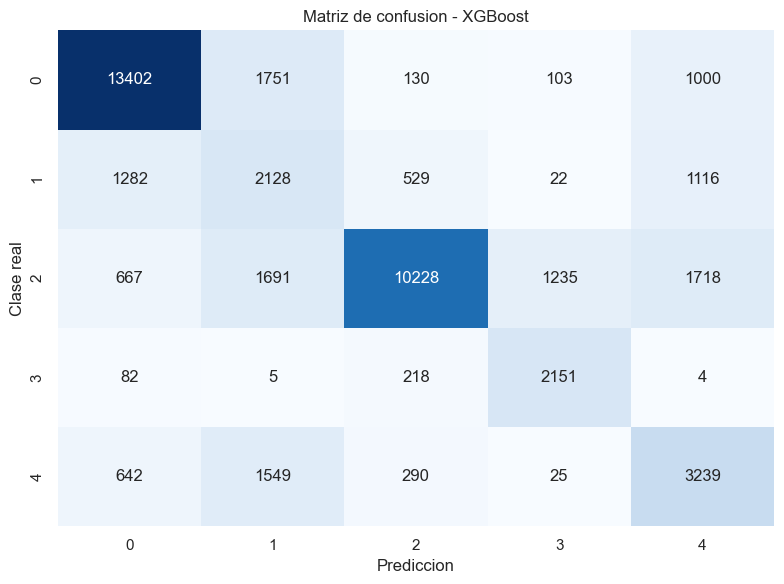

,0,1,2,3,4
0,13402,1751,130,103,1000
1,1282,2128,529,22,1116
2,667,1691,10228,1235,1718
3,82,5,218,2151,4
4,642,1549,290,25,3239


In [18]:
conf_matrix = confusion_matrix(y_test, y_pred, labels=np.arange(len(class_labels)))
conf_matrix_df = pd.DataFrame(conf_matrix, index=class_labels, columns=class_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Matriz de confusion - XGBoost")
plt.xlabel("Prediccion")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

display(conf_matrix_df)

## Importancia de variables

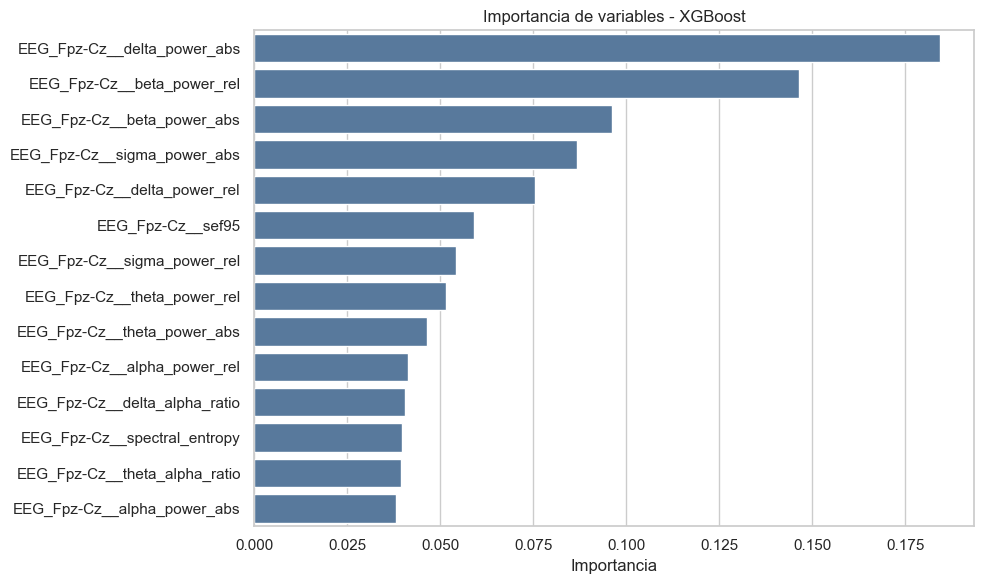

,feature,importance
0,EEG_Fpz-Cz__delta_power_abs,0.184249
9,EEG_Fpz-Cz__beta_power_rel,0.146374
8,EEG_Fpz-Cz__beta_power_abs,0.096274
6,EEG_Fpz-Cz__sigma_power_abs,0.086652
1,EEG_Fpz-Cz__delta_power_rel,0.075425
12,EEG_Fpz-Cz__sef95,0.059183
7,EEG_Fpz-Cz__sigma_power_rel,0.054381
3,EEG_Fpz-Cz__theta_power_rel,0.051461
2,EEG_Fpz-Cz__theta_power_abs,0.046523
5,EEG_Fpz-Cz__alpha_power_rel,0.041383


In [19]:
feature_importance = pd.DataFrame(
    {
        "feature": feature_columns,
        "importance": best_model.feature_importances_,
    }
).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x="importance", y="feature", color="#4C78A8")
plt.title("Importancia de variables - XGBoost")
plt.xlabel("Importancia")
plt.ylabel("")
plt.tight_layout()
plt.show()

display(feature_importance)